# DAV Lab-3
## Data Transformation & Analysis
### Name: Piyush Khokale
### Class: A-A2
### Roll No: 17

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## Step 2,3: Create/Load Dataset

In [2]:
df = pd.read_csv('StudentsPerformance.xls')
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## Step 4: Explore dataset

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [5]:
df.shape

(1000, 8)

In [6]:
df.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

In [7]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [8]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## Step 5: Data Cleaning

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()
df.shape

(1000, 8)

In [11]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [12]:
df = df.rename(columns={
    'parental level of education': 'parent_education',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score',
    'race/ethnicity': 'race'
})
df.columns

Index(['gender', 'race', 'parent_education', 'lunch', 'test_prep',
       'math_score', 'reading_score', 'writing_score'],
      dtype='str')

## Step 6: Normalization

In [13]:
scaler = MinMaxScaler()
score_cols = ['math_score', 'reading_score', 'writing_score']
df_norm = df.copy()
df_norm[score_cols] = scaler.fit_transform(df[score_cols])
df_norm[score_cols].head()

,math_score,reading_score,writing_score
0,0.72,0.662651,0.711111
1,0.69,0.879518,0.866667
2,0.90,0.939759,0.922222
3,0.47,0.481928,0.377778
4,0.76,0.734940,0.722222


## Step 7: Scaling

In [14]:
std_scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[score_cols] = std_scaler.fit_transform(df[score_cols])
df_scaled[score_cols].head()

,math_score,reading_score,writing_score
0,0.390024,0.193999,0.391492
1,0.192076,1.427476,1.313269
2,1.577711,1.770109,1.642475
3,-1.259543,-0.833899,-1.583744
4,0.653954,0.605158,0.457333


In [15]:
df_scaled[score_cols].describe()

,math_score,reading_score,writing_score
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,8.704149e-17,2.167155e-16,-1.350031e-16
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-4.360728e+00,-3.574960e+00,-3.822345e+00
25%,-5.997164e-01,-6.968462e-01,-6.784278e-01
50%,-5.872457e-03,5.694554e-02,6.228578e-02
75%,7.199368e-01,6.736842e-01,7.206978e-01
max,2.237538e+00,2.112741e+00,2.103363e+00


## Step 8: Encoding 

### Label Encoding

In [16]:
le = LabelEncoder()
df['gender_encoded'] = le.fit_transform(df['gender'])
df[['gender', 'gender_encoded']].head()

,gender,gender_encoded
0,female,0
1,female,0
2,female,0
3,male,1
4,male,1


### One-Hot Encoding

In [17]:
race_dummies = pd.get_dummies(df['race'], prefix='race')
df = pd.concat([df, race_dummies], axis=1)
race_dummies.head()

,race_group A,race_group B,race_group C,race_group D,race_group E
0,False,True,False,False,False
1,False,False,True,False,False
2,False,True,False,False,False
3,True,False,False,False,False
4,False,False,True,False,False


## Step 9: Aggregation

### Average scores by gender

In [18]:
df.groupby('gender')[score_cols].mean()

,math_score,reading_score,writing_score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


### Maximum scores by race

In [19]:
df.groupby('race')[score_cols].max()

,math_score,reading_score,writing_score
race,,,
group A,100,100,97
group B,97,97,96
group C,98,100,100
group D,100,100,100
group E,100,100,100


### Total students by lunch type

In [20]:
df.groupby('lunch').size()

lunch
free/reduced    355
standard        645
dtype: int64

### Average scores and count by parent education

In [21]:
df.groupby('parent_education')[score_cols].agg(['mean', 'count'])

math_score       reading_score       writing_score      
                         mean count          mean count          mean count
parent_education                                                           
associate's degree  67.882883   222     70.927928   222     69.896396   222
bachelor's degree   69.389831   118     73.000000   118     73.381356   118
high school         62.137755   196     64.704082   196     62.448980   196
master's degree     69.745763    59     75.372881    59     75.677966    59
some college        67.128319   226     69.460177   226     68.840708   226
some high school    63.497207   179     66.938547   179     64.888268   179

## Step 10: Binning

### Bin math scores into categories

In [22]:
bins = [0, 40, 60, 80, 100]
labels = ['Fail', 'Average', 'Good', 'Excellent']
df['math_grade'] = pd.cut(df['math_score'], bins=bins, labels=labels)
df[['math_score', 'math_grade']].head(10)

,math_score,math_grade
0,72,Good
1,69,Good
2,90,Excellent
3,47,Average
4,76,Good
5,71,Good
6,88,Excellent
7,40,Fail
8,64,Good
9,38,Fail


### Distribution of math grades

In [23]:
df['math_grade'].value_counts()

math_grade
Good         485
Average      289
Excellent    176
Fail          49
Name: count, dtype: int64

## Step 11: Statistical Analysis

In [24]:
stats = pd.DataFrame(index=['mean', 'median', 'mode', 'std', 'var', 'range', 'min', 'max', 'Q1', 'Q3'])
for col in score_cols:
    stats[col] = [
        df[col].mean(),
        df[col].median(),
        df[col].mode()[0],
        df[col].std(),
        df[col].var(),
        df[col].max() - df[col].min(),
        df[col].min(),
        df[col].max(),
        df[col].quantile(0.25),
        df[col].quantile(0.75)
    ]
stats

,math_score,reading_score,writing_score
mean,66.089000,69.169000,68.054000
median,66.000000,70.000000,69.000000
mode,65.000000,72.000000,74.000000
std,15.163080,14.600192,15.195657
var,229.918998,213.165605,230.907992
range,100.000000,83.000000,90.000000
min,0.000000,17.000000,10.000000
max,100.000000,100.000000,100.000000
Q1,57.000000,59.000000,57.750000
Q3,77.000000,79.000000,79.000000


## Step 12: Correlation Analysis

In [25]:
corr = df[score_cols].corr()
corr

,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


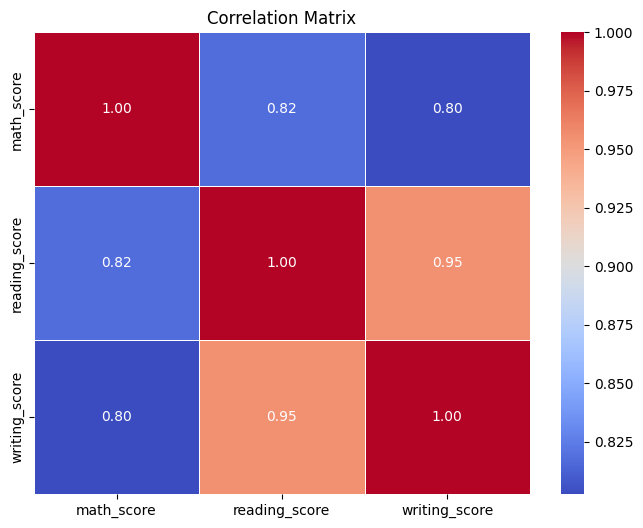

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

## Step 13: Regression Analysis

### Predict writing score using reading score

In [27]:
X = df[['reading_score']]
y = df['writing_score']

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['reading_score']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.896
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [30]:
y_pred = model.predict(X_test)
compare = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
compare.head(10)

,Actual,Predicted
0,84,84.853307
1,73,64.911614
2,72,71.891207
3,73,75.879545
4,78,81.862053
5,78,73.885376
6,63,68.899953
7,62,59.926191
8,72,71.891207
9,41,52.946598


In [31]:
print('Coefficient:', model.coef_[0])
print('Intercept:', model.intercept_)
print('R2 Score:', r2_score(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

Coefficient: 0.9970846425825851
Intercept: -0.8959723148317238
R2 Score: 0.9009597530871629
RMSE: 4.88573236211165


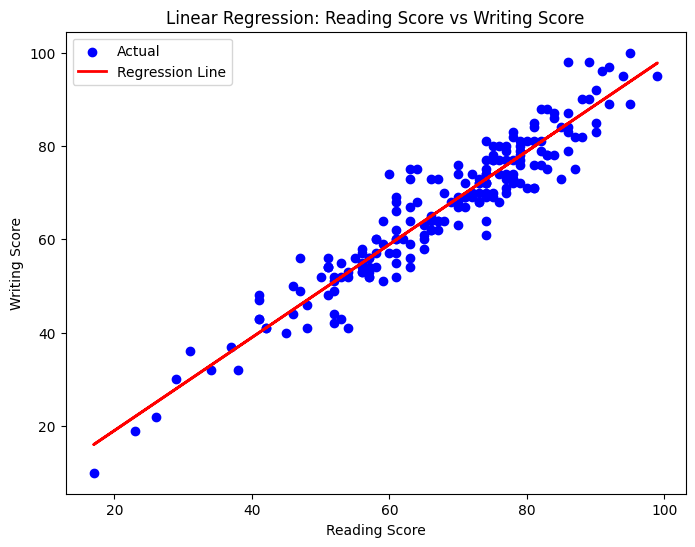

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', label='Actual')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Reading Score')
plt.ylabel('Writing Score')
plt.title('Linear Regression: Reading Score vs Writing Score')
plt.legend()
plt.show()